In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from collections import defaultdict
from tqdm import tqdm
import keras_cv


C:\Users\suram\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_DIR = "Skin Disease Dataset"

IMG_SIZE = 224
INPUT_SHAPE = (224, 224, 3)
BATCH_SIZE = 32


In [3]:
classes = sorted(os.listdir(DATA_DIR))
num_classes = len(classes)

print("Classes:", classes)
print("Number of classes:", num_classes)


Classes: ['Acitinic Keratosis', 'Dermatofibroma', 'Nevus', 'Pigmented Benign Keratosis', 'Seborrheic Keratosis', 'Vascular Lesion']
Number of classes: 6


In [4]:
data_dict = defaultdict(list)
root_images = []
root_labels = []
error_count = 0

for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)
    images = os.listdir(class_path)

    for img_name in tqdm(images, desc=f"Loading {class_name}"):
        try:
            img_path = os.path.join(class_path, img_name)
            image = cv2.imread(img_path)
            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            data_dict[class_name].append(image)
            root_images.append(image)
            root_labels.append(class_name)
        except:
            error_count += 1

print("Errors:", error_count)
print("Total images loaded:", len(root_images))

Loading Vascular Lesion: 100%|██████████| 290/290 [00:05<00:00, 56.21it/s] 

Errors: 2
Total images loaded: 2688


Acitinic Keratosis            500
Nevus                         500
Pigmented Benign Keratosis    500
Seborrheic Keratosis          500
Dermatofibroma                399
Vascular Lesion               289
dtype: int64


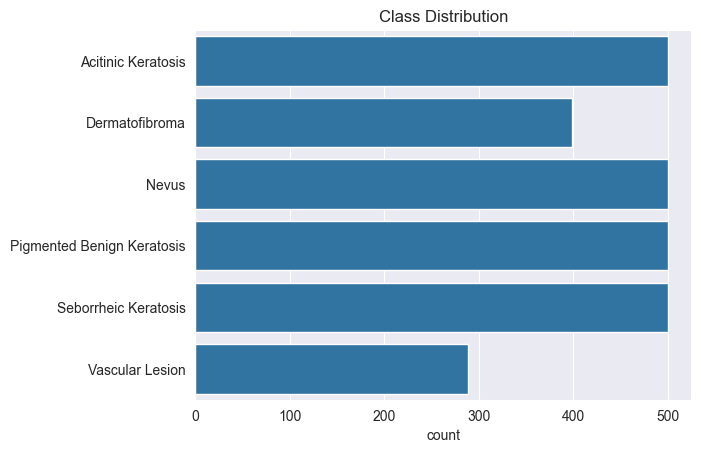

In [5]:
label_counts = pd.Series(root_labels).value_counts()
print(label_counts)

sns.countplot(y=root_labels)
plt.title("Class Distribution")
plt.show()


In [6]:
x_arr = np.array(root_images, dtype=np.float32)

y_arr = tf.one_hot(
    [classes.index(lbl) for lbl in root_labels],
    num_classes
).numpy()

print(x_arr.shape, y_arr.shape)


(2688, 224, 224, 3) (2688, 6)


In [7]:
image_per_class = 1000
mix_per_batch = 42

mixup = keras_cv.layers.Augmenter([keras_cv.layers.MixUp()])

root_label_df = pd.DataFrame({"dx": root_labels})
count_dict = {label: len(imgs) for label, imgs in data_dict.items()}

x_tensor = tf.constant(x_arr)
y_tensor = tf.constant(y_arr)

x_tensor_mix, y_tensor_mix = None, None

for label, count in count_dict.items():
    num_mix = ((image_per_class - count) // mix_per_batch) * mix_per_batch

    for _ in range(num_mix // mix_per_batch):
        idx = np.random.choice(
            root_label_df[root_label_df.dx == label].index,
            mix_per_batch,
            replace=False
        )

        mix_out = mixup({
            "images": tf.gather(x_tensor, idx),
            "labels": tf.gather(y_tensor, idx)
        })

        if x_tensor_mix is None:
            x_tensor_mix = mix_out["images"]
            y_tensor_mix = mix_out["labels"]
        else:
            x_tensor_mix = tf.concat([x_tensor_mix, mix_out["images"]], axis=0)
            y_tensor_mix = tf.concat([y_tensor_mix, mix_out["labels"]], axis=0)

x = np.concatenate([x_arr, x_tensor_mix.numpy()], axis=0)
y = np.concatenate([y_arr, y_tensor_mix.numpy()], axis=0)

print(x.shape, y.shape)


(5796, 224, 224, 3) (5796, 6)


In [8]:
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)


In [9]:
from tensorflow.keras import layers

# -------------------------------
# Channel Attention
# -------------------------------
def channel_attention(input_feature, ratio=8):
    channel = input_feature.shape[-1]

    shared_dense_1 = layers.Dense(channel // ratio, activation='relu')
    shared_dense_2 = layers.Dense(channel)

    avg_pool = layers.GlobalAveragePooling2D()(input_feature)
    avg_pool = layers.Reshape((1, 1, channel))(avg_pool)
    avg_pool = shared_dense_2(shared_dense_1(avg_pool))

    max_pool = layers.GlobalMaxPooling2D()(input_feature)
    max_pool = layers.Reshape((1, 1, channel))(max_pool)
    max_pool = shared_dense_2(shared_dense_1(max_pool))

    attention = layers.Activation('sigmoid')(avg_pool + max_pool)
    return layers.Multiply()([input_feature, attention])


# -------------------------------
# Spatial Attention (FIXED)
# -------------------------------
def spatial_attention(input_feature):
    avg_pool = layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=-1, keepdims=True)
    )(input_feature)

    max_pool = layers.Lambda(
        lambda x: tf.reduce_max(x, axis=-1, keepdims=True)
    )(input_feature)

    concat = layers.Concatenate(axis=-1)([avg_pool, max_pool])

    attention = layers.Conv2D(
        filters=1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(concat)

    return layers.Multiply()([input_feature, attention])


# -------------------------------
# CBAM Block
# -------------------------------
def cbam_block(x):
    x = channel_attention(x)
    x = spatial_attention(x)
    return x


In [10]:
from tensorflow.keras.applications import MobileNetV3Large

base_model = MobileNetV3Large(
    weights="imagenet",
    include_top=False,
    input_shape=INPUT_SHAPE
)

base_model.trainable = False  # Transfer learning

x = base_model.output
x = cbam_block(x)              # 🔥 CBAM ADDED HERE
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

output = layers.Dense(num_classes, activation="softmax")(x)

model = Model(base_model.input, output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ rescaling[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        144 │ activation[0][0]  │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        256 │ re_lu[0][0]       │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_add   │ (None, 112, 112,  │          0 │ activation[0][0], │
│ (Add)               │ 16)               │            │ expanded_conv_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │      1,024 │ expanded_conv_ad… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │        256 │ expanded_conv_1_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 112, 112,  │          0 │ expanded_conv_1_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 113, 113,  │          0 │ re_lu_1[0][0]     │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        576 │ expanded_conv_1_… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        256 │ expanded_conv_1_

 Total params: 3,479,329 (13.27 MB)

 Trainable params: 481,057 (1.84 MB)

 Non-trainable params: 2,998,272 (11.44 MB)

In [11]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)


Epoch 1/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 66s 417ms/step - accuracy: 0.2322 - loss: 1.9716 - val_accuracy: 0.5069 - val_loss: 1.6114
Epoch 2/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 56s 386ms/step - accuracy: 0.4953 - loss: 1.3112 - val_accuracy: 0.6379 - val_loss: 1.1751
Epoch 3/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 56s 387ms/step - accuracy: 0.6503 - loss: 0.9488 - val_accuracy: 0.7259 - val_loss: 0.8733
Epoch 4/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 82s 565ms/step - accuracy: 0.7136 - loss: 0.7804 - val_accuracy: 0.7793 - val_loss: 0.6675
Epoch 5/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 55s 380ms/step - accuracy: 0.7669 - loss: 0.6490 - val_accuracy: 0.8086 - val_loss: 0.5697
Epoch 6/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 55s 380ms/step - accuracy: 0.8344 - loss: 0.5060 - val_accuracy: 0.8241 - val_loss: 0.4858
Epoch 7/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 35s 240ms/step - accuracy: 0.8500 - loss: 0.4399 - val_accuracy: 0.8448 - val_loss: 0.4205
Epoch 8/25
145/145 ━━━━━━━━━━━━━━━━━━━━ 36s 245ms/step - accuracy: 0.8827 - loss: 0

In [12]:
loss, acc = model.evaluate(x_test, y_test)
print("Test Accuracy:", acc)

19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 253ms/step - accuracy: 0.9349 - loss: 0.2442
Test Accuracy: 0.9362068772315979


In [13]:
y_pred = np.argmax(model.predict(x_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=classes))



19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 349ms/step
                            precision    recall  f1-score   support

        Acitinic Keratosis       0.93      0.93      0.93        96
            Dermatofibroma       0.95      0.95      0.95        99
                     Nevus       0.97      0.98      0.97        96
Pigmented Benign Keratosis       0.92      0.90      0.91        96
      Seborrheic Keratosis       0.88      0.87      0.87        97
           Vascular Lesion       0.97      1.00      0.98        96

                  accuracy                           0.94       580
                 macro avg       0.94      0.94      0.94       580
              weighted avg       0.94      0.94      0.94       580



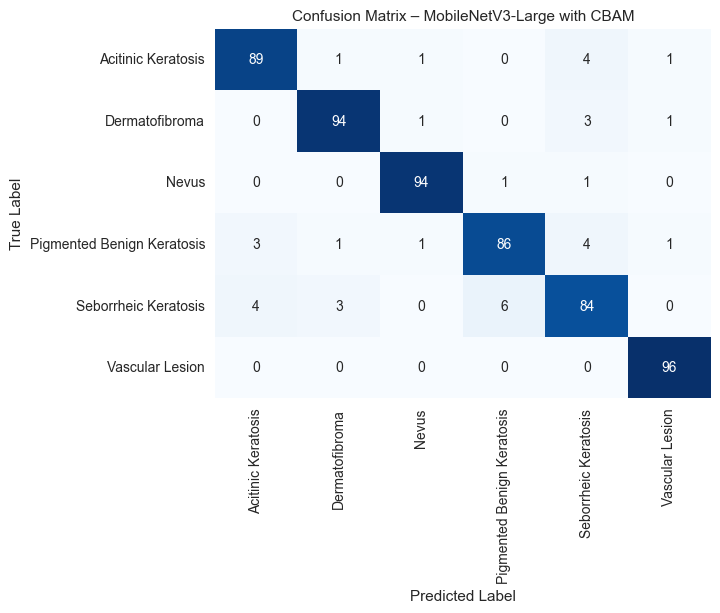

In [14]:
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=classes,
            yticklabels=classes,
            cmap="Blues",
            cbar=False)
plt.title("Confusion Matrix – MobileNetV3-Large with CBAM", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("True Label", fontsize=11)
cbar=False
plt.show()


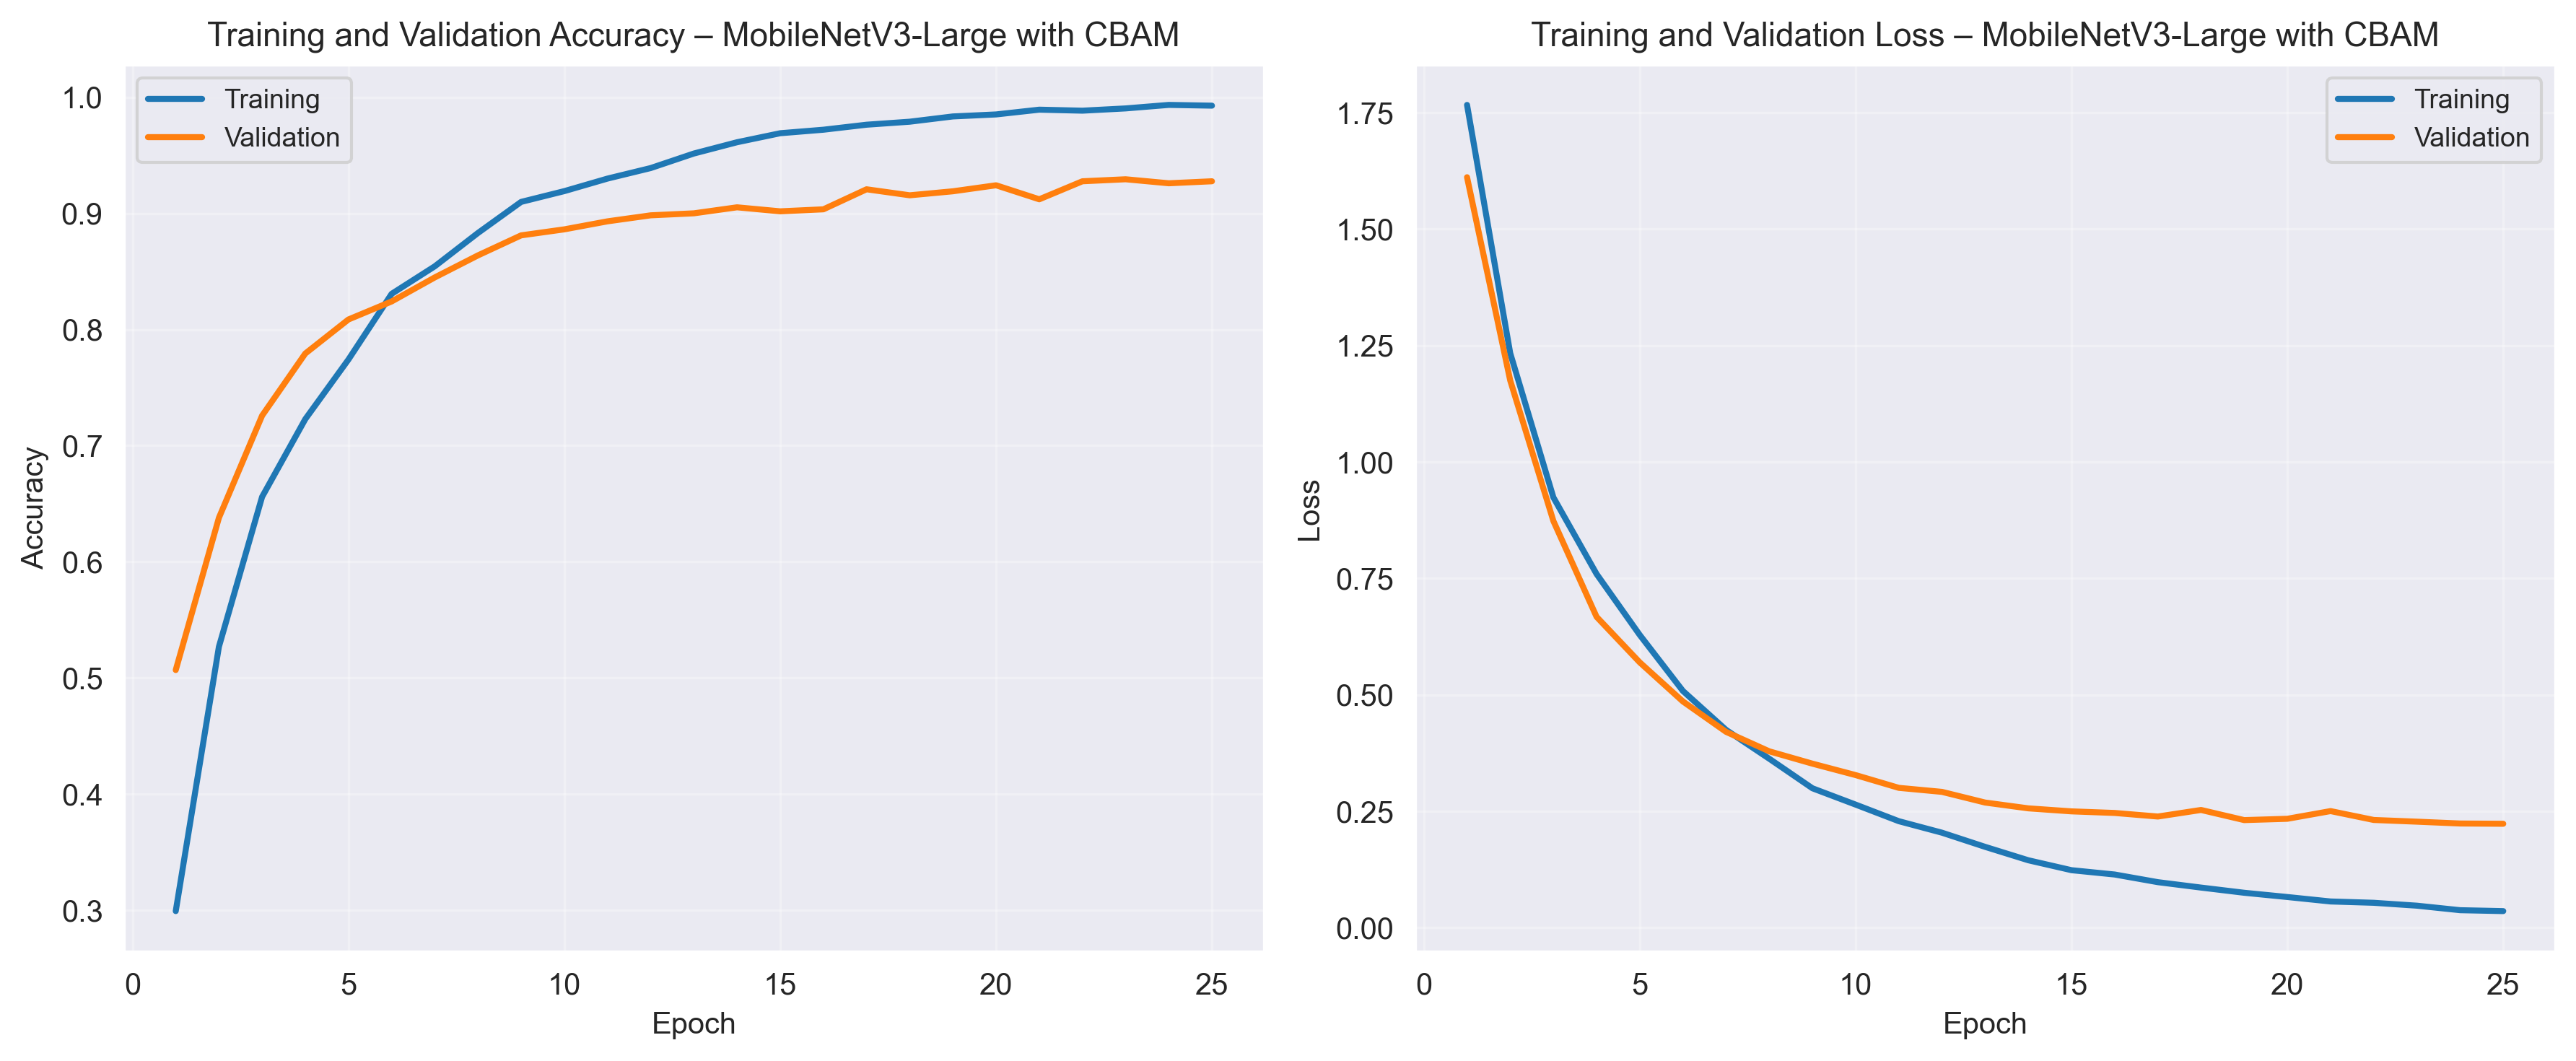

In [15]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(12, 5), dpi=300)

# ---------------- Accuracy Plot ----------------
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'],
         linewidth=2, label='Training')
plt.plot(epochs_range, history.history['val_accuracy'],
         linewidth=2, label='Validation')

plt.title("Training and Validation Accuracy – MobileNetV3-Large with CBAM", fontsize=11)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)

# ---------------- Loss Plot ----------------
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'],
         linewidth=2, label='Training')
plt.plot(epochs_range, history.history['val_loss'],
         linewidth=2, label='Validation')

plt.title("Training and Validation Loss – MobileNetV3-Large with CBAM", fontsize=11)
plt.xlabel("Epoch", fontsize=10)
plt.ylabel("Loss", fontsize=10)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()

# Save high-resolution image for paper
plt.savefig("training_curves_mobilenetv3_cbam.png",
            dpi=300, bbox_inches='tight')

plt.show()


19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step


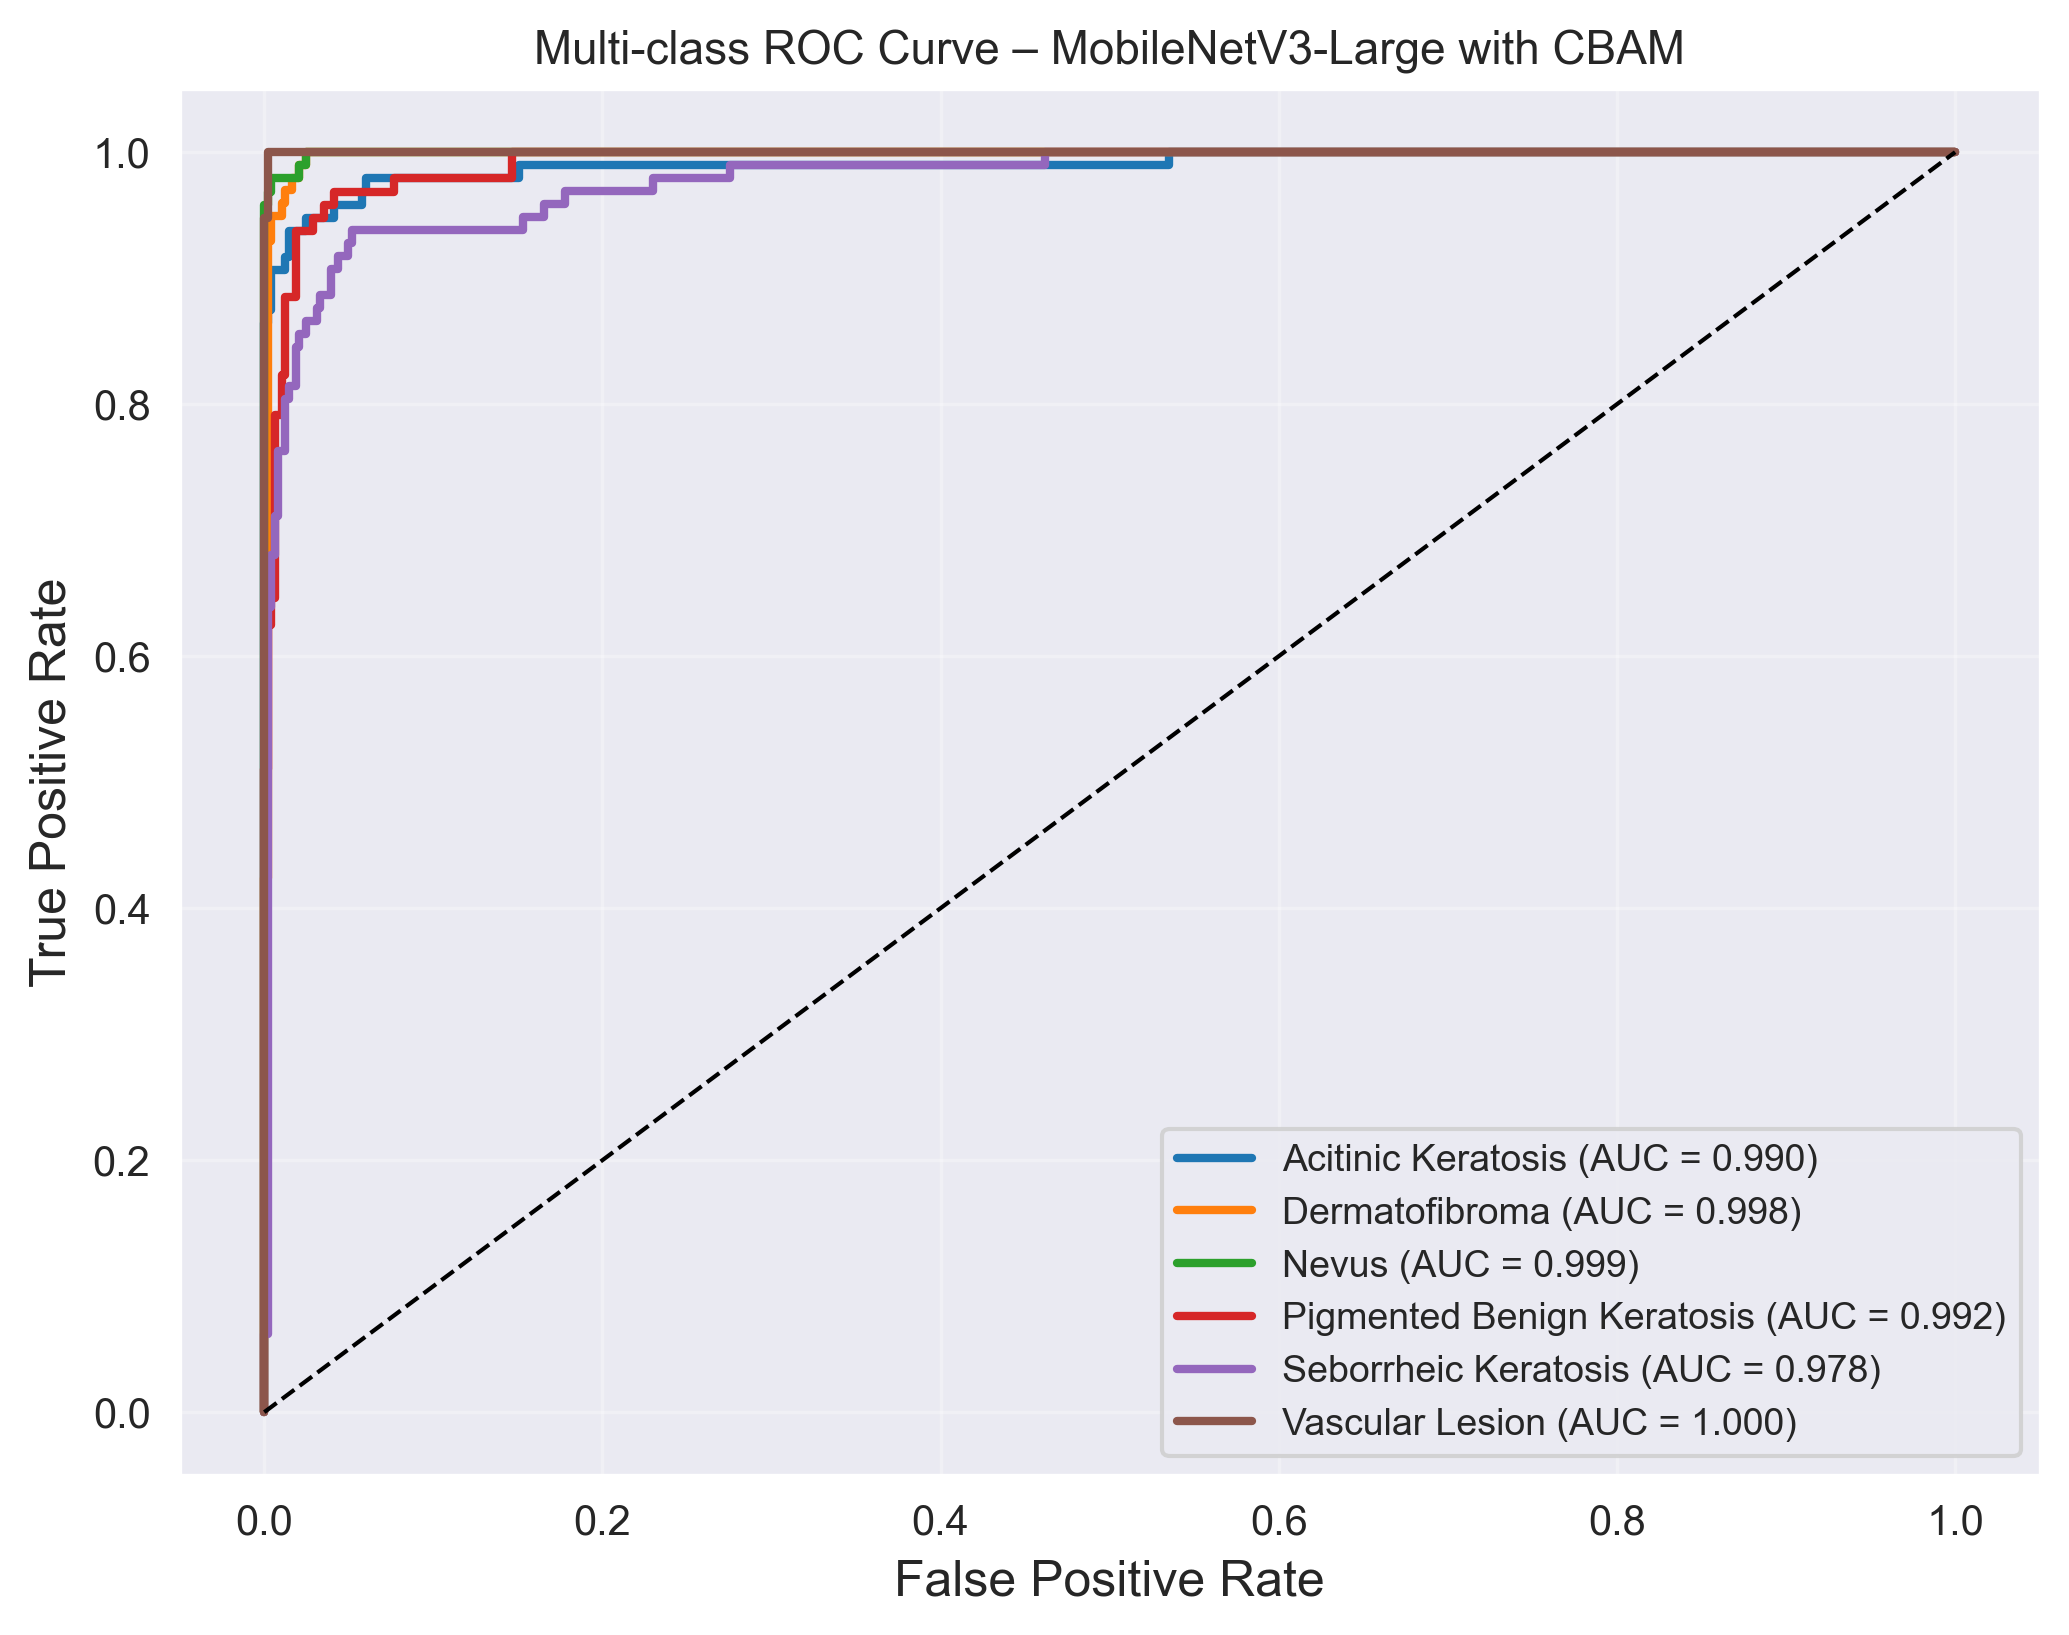

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Predict probabilities
y_score = model.predict(x_test)

# Convert true labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

y_true_bin = label_binarize(y_true, classes=range(n_classes))

# Compute ROC curve and AUC
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Create high-quality figure
plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], linewidth=2,
             label=f"{classes[i]} (AUC = {roc_auc[i]:.3f})")

# Random classifier
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("Multi-class ROC Curve – MobileNetV3-Large with CBAM", fontsize=11)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)

# Save for research paper
plt.savefig("roc_curve.png", dpi=300, bbox_inches='tight')

plt.show()


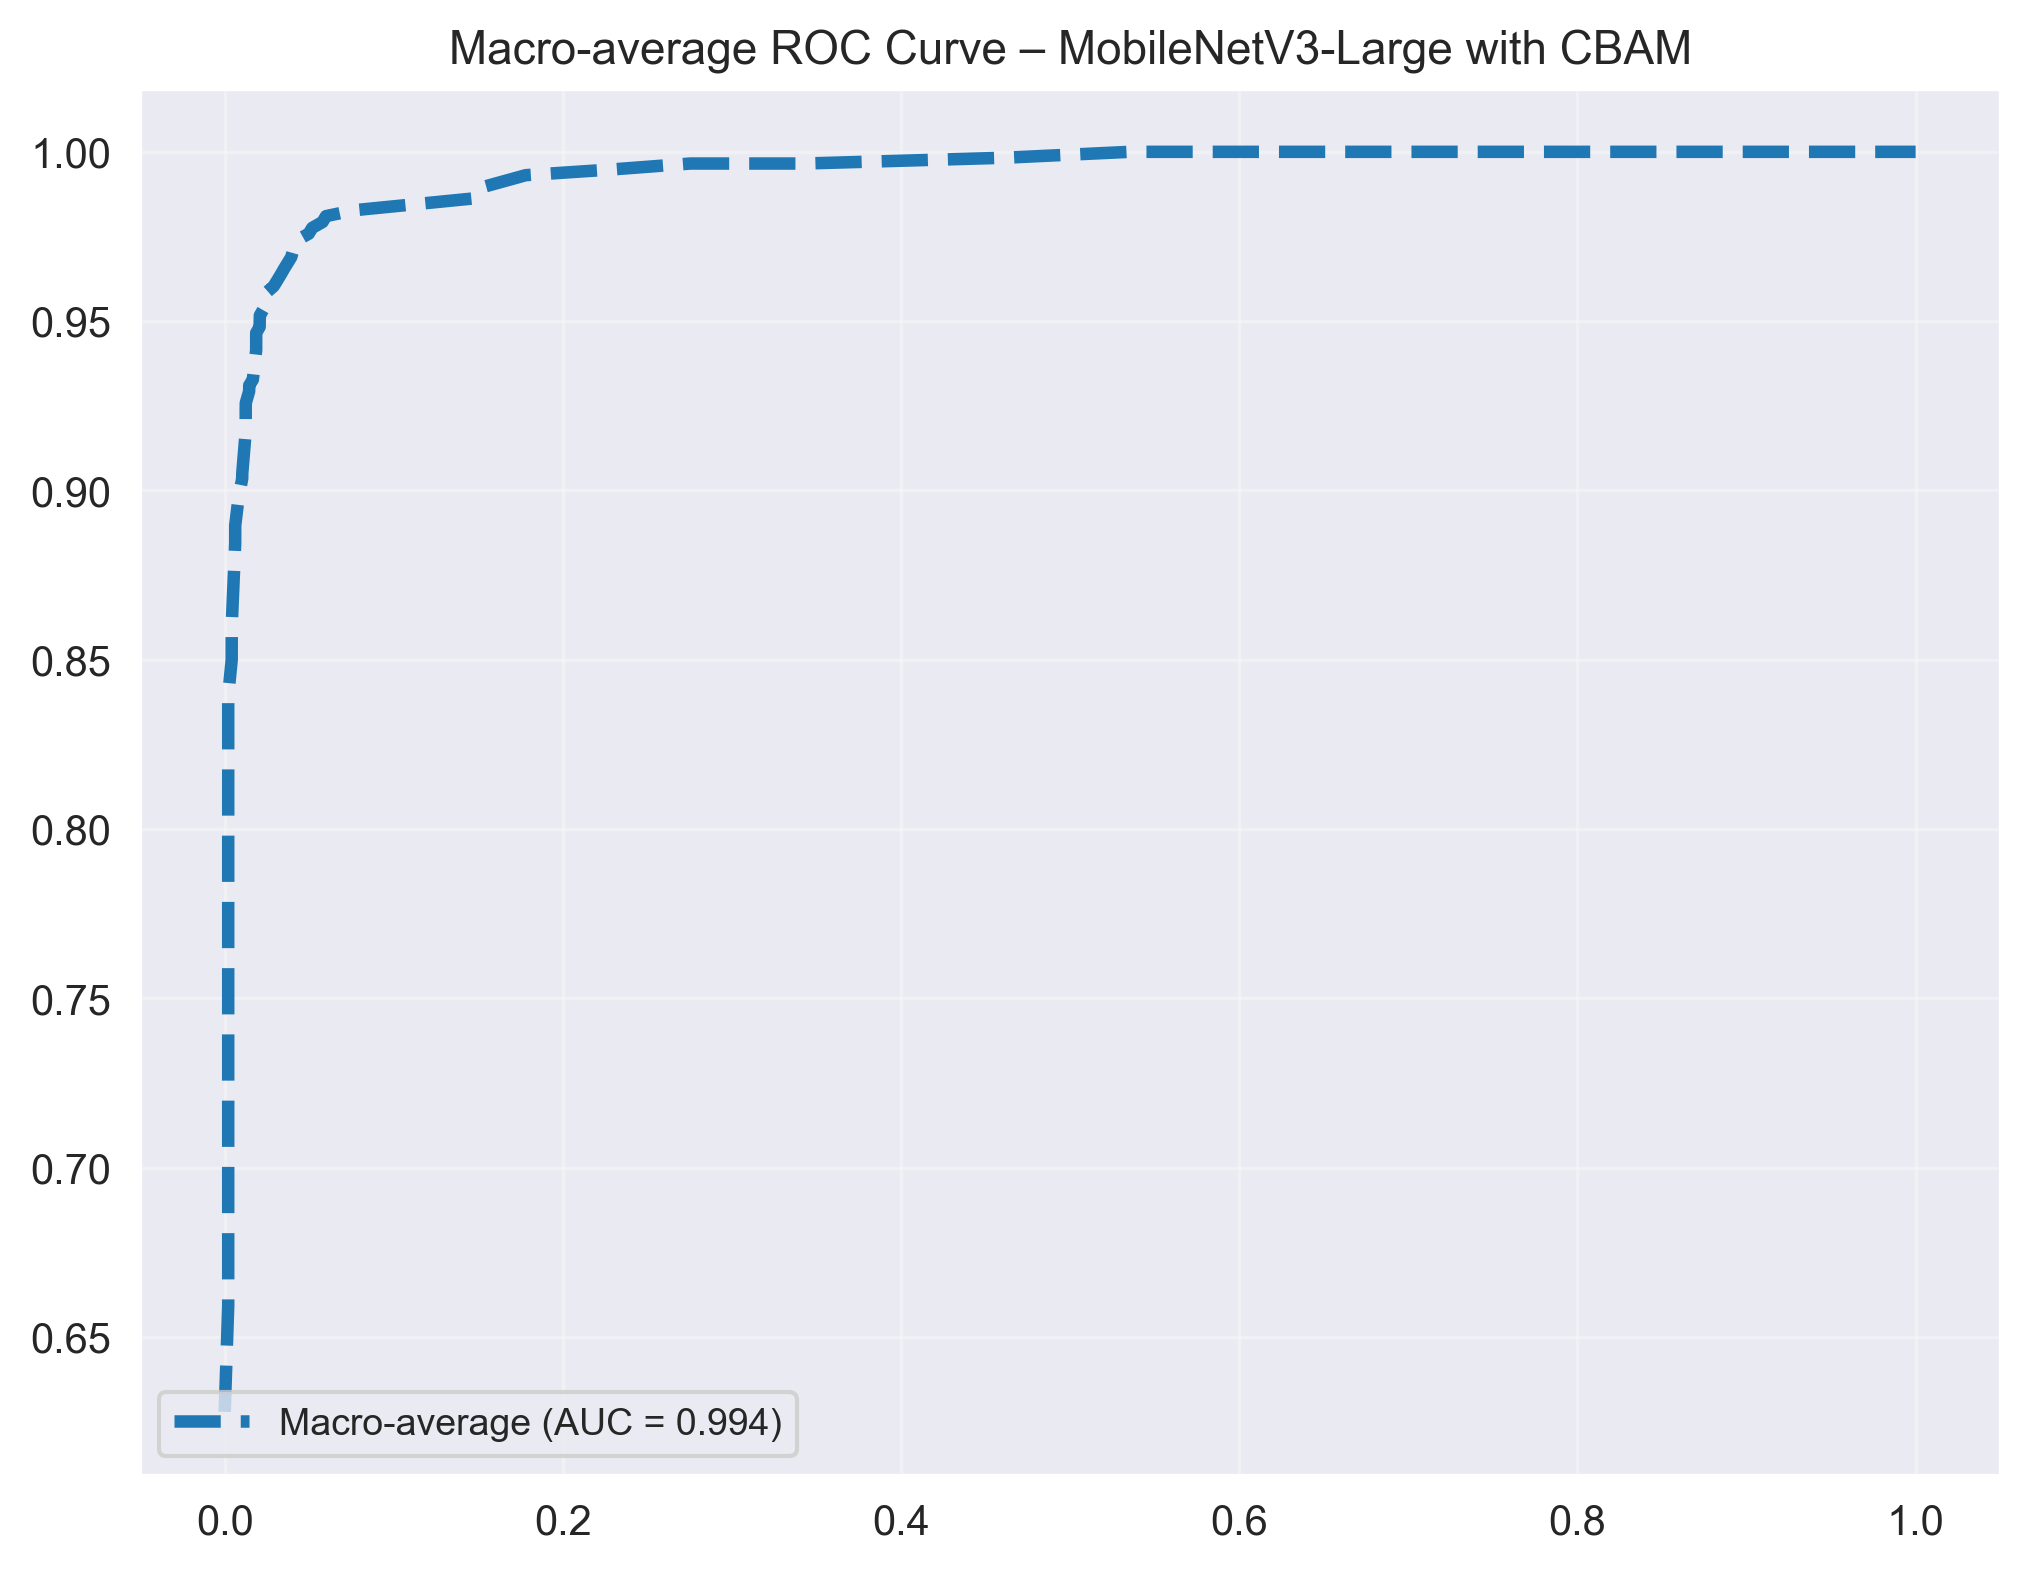

In [17]:
# Compute macro-average ROC
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)

for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= n_classes
macro_auc = auc(all_fpr, mean_tpr)
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(all_fpr, mean_tpr, linestyle='--', linewidth=3,
         label=f"Macro-average (AUC = {macro_auc:.3f})")
plt.title("Macro-average ROC Curve – MobileNetV3-Large with CBAM", fontsize=11)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

plt.show()

In [18]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(y_test, y_score, average='macro')
weighted_auc = roc_auc_score(y_test, y_score, average='weighted')

print("Macro AUC:", macro_auc)
print("Weighted AUC:", weighted_auc)


Macro AUC: 0.9929541200388011
Weighted AUC: 0.9929548936789635


19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 199ms/step


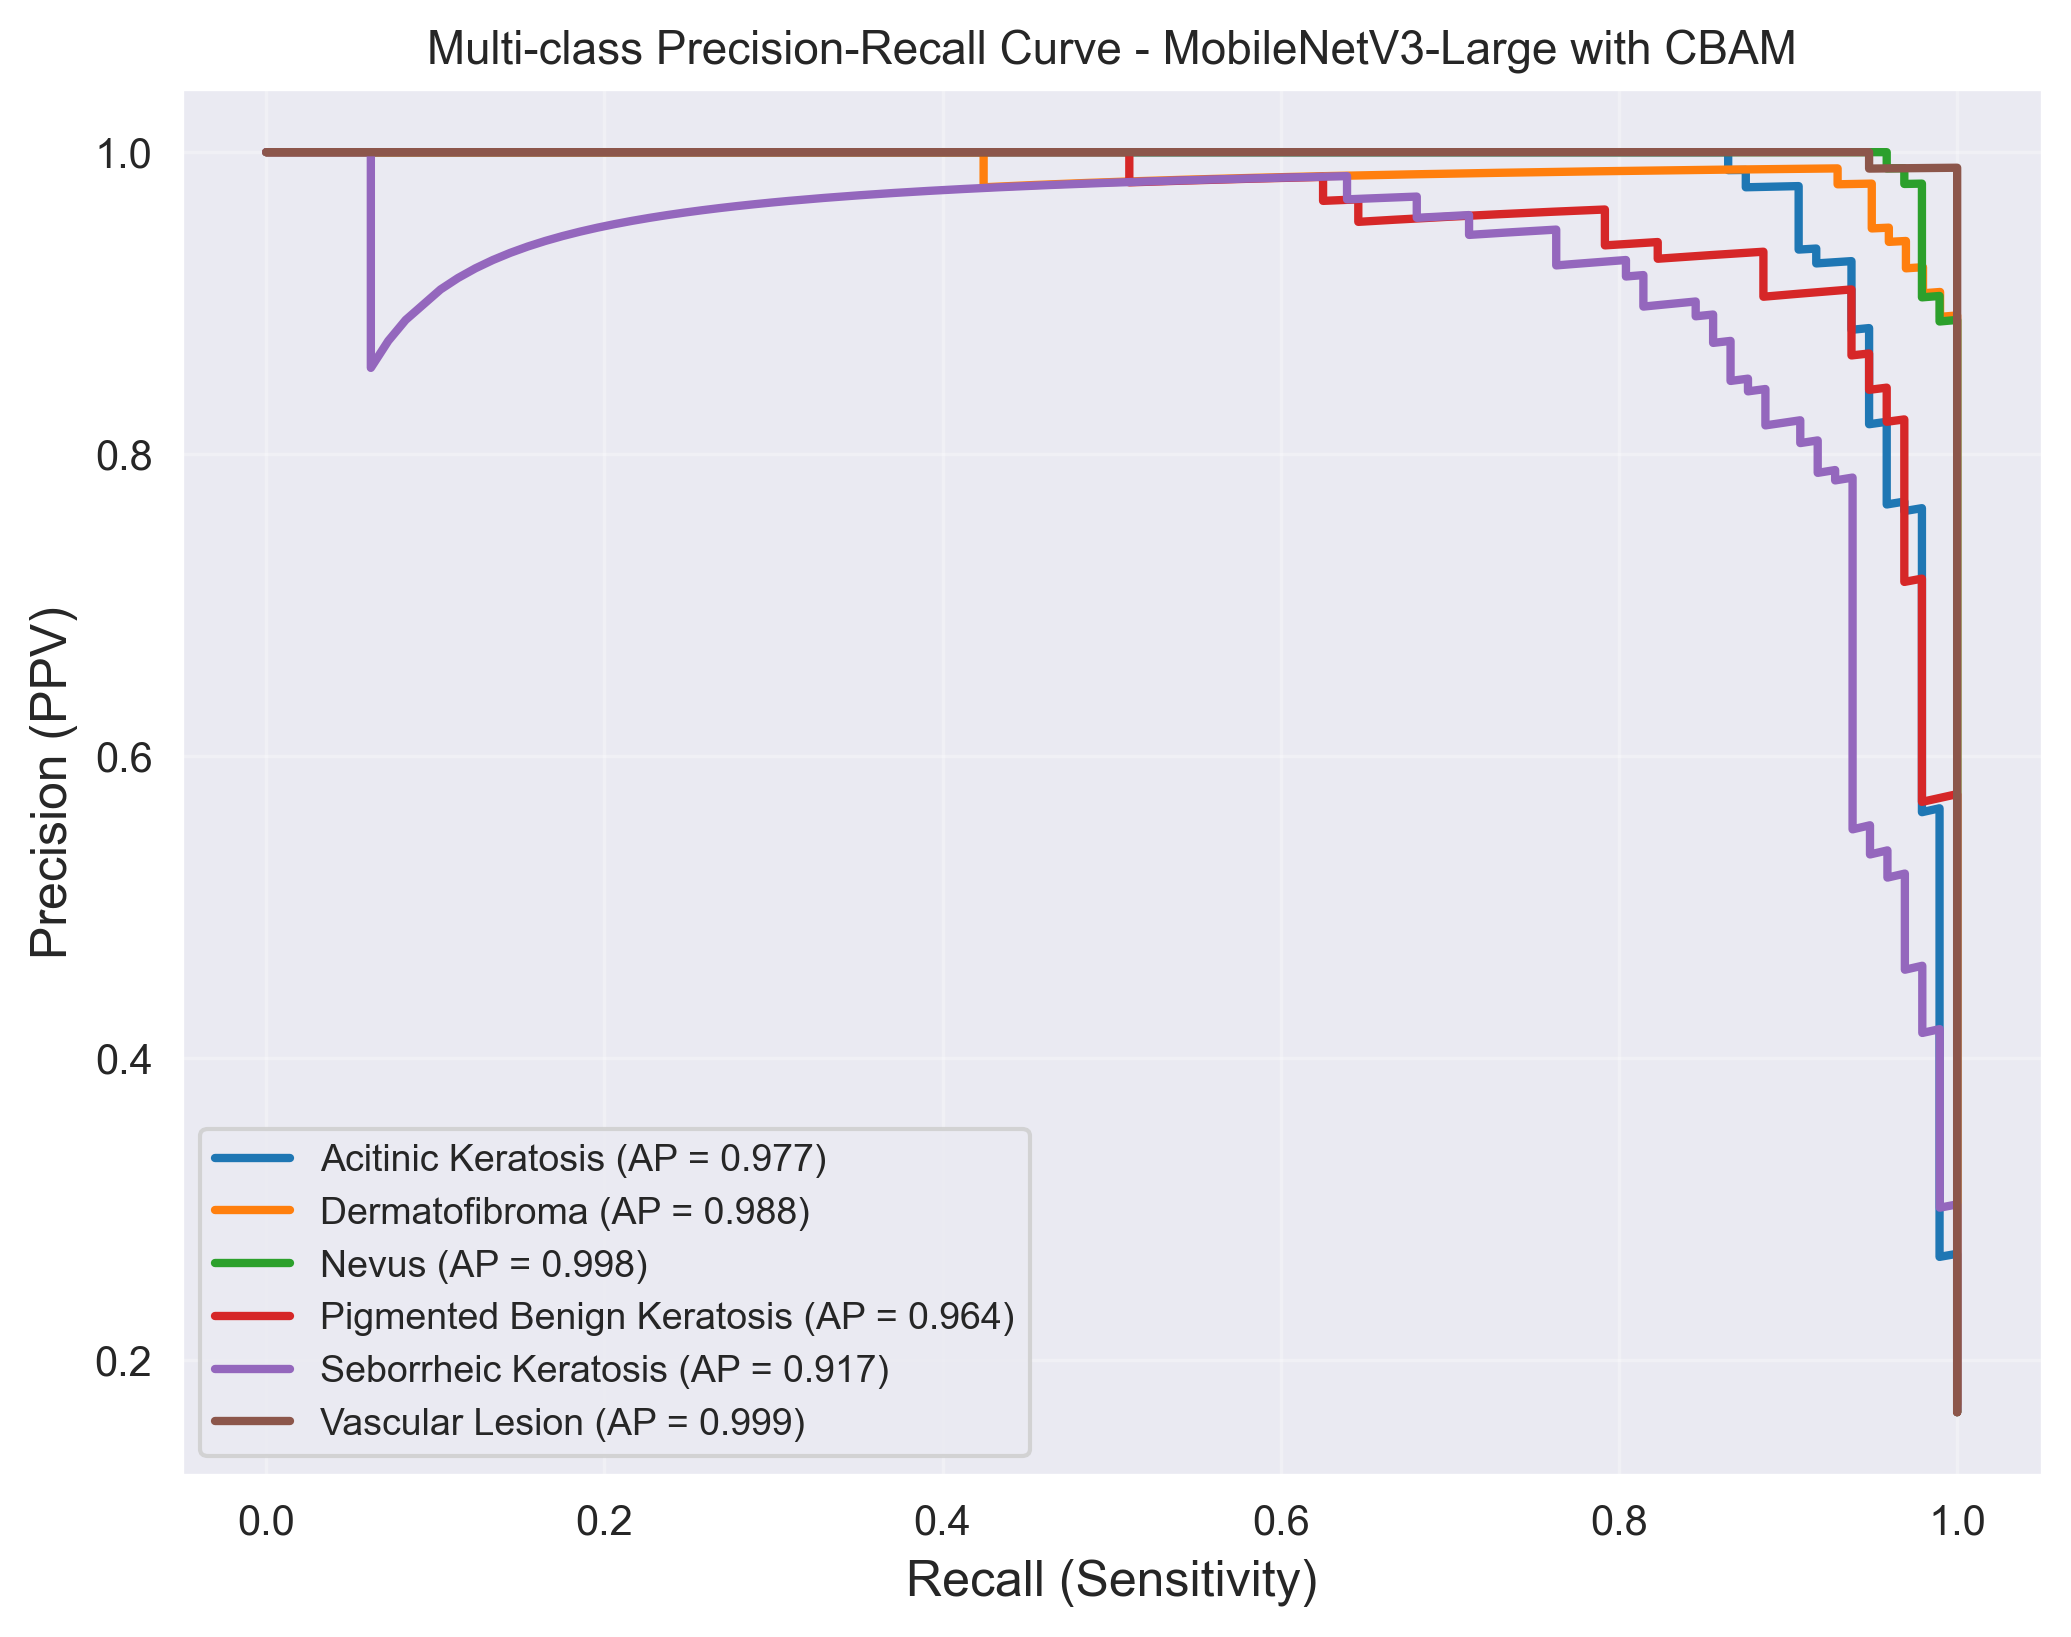

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Predict probabilities (NOT argmax)
y_score = model.predict(x_test)

# Convert true labels
y_true = np.argmax(y_test, axis=1)
n_classes = y_test.shape[1]

y_true_bin = label_binarize(y_true, classes=range(n_classes))

precision = dict()
recall = dict()
avg_precision = dict()

# Compute PR curve and Average Precision (AP) for each class
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(
        y_true_bin[:, i], y_score[:, i]
    )
    avg_precision[i] = average_precision_score(
        y_true_bin[:, i], y_score[:, i]
    )

# Create high-quality figure
plt.figure(figsize=(8, 6), dpi=300)

for i in range(n_classes):
    plt.plot(recall[i], precision[i], linewidth=2,
             label=f"{classes[i]} (AP = {avg_precision[i]:.3f})")

plt.xlabel("Recall (Sensitivity)", fontsize=12)
plt.ylabel("Precision (PPV)", fontsize=12)
plt.title("Multi-class Precision-Recall Curve - MobileNetV3-Large with CBAM", fontsize=11)
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)

# Save high-resolution image
plt.savefig("precision_recall_curve.png", dpi=300, bbox_inches='tight')

plt.show()


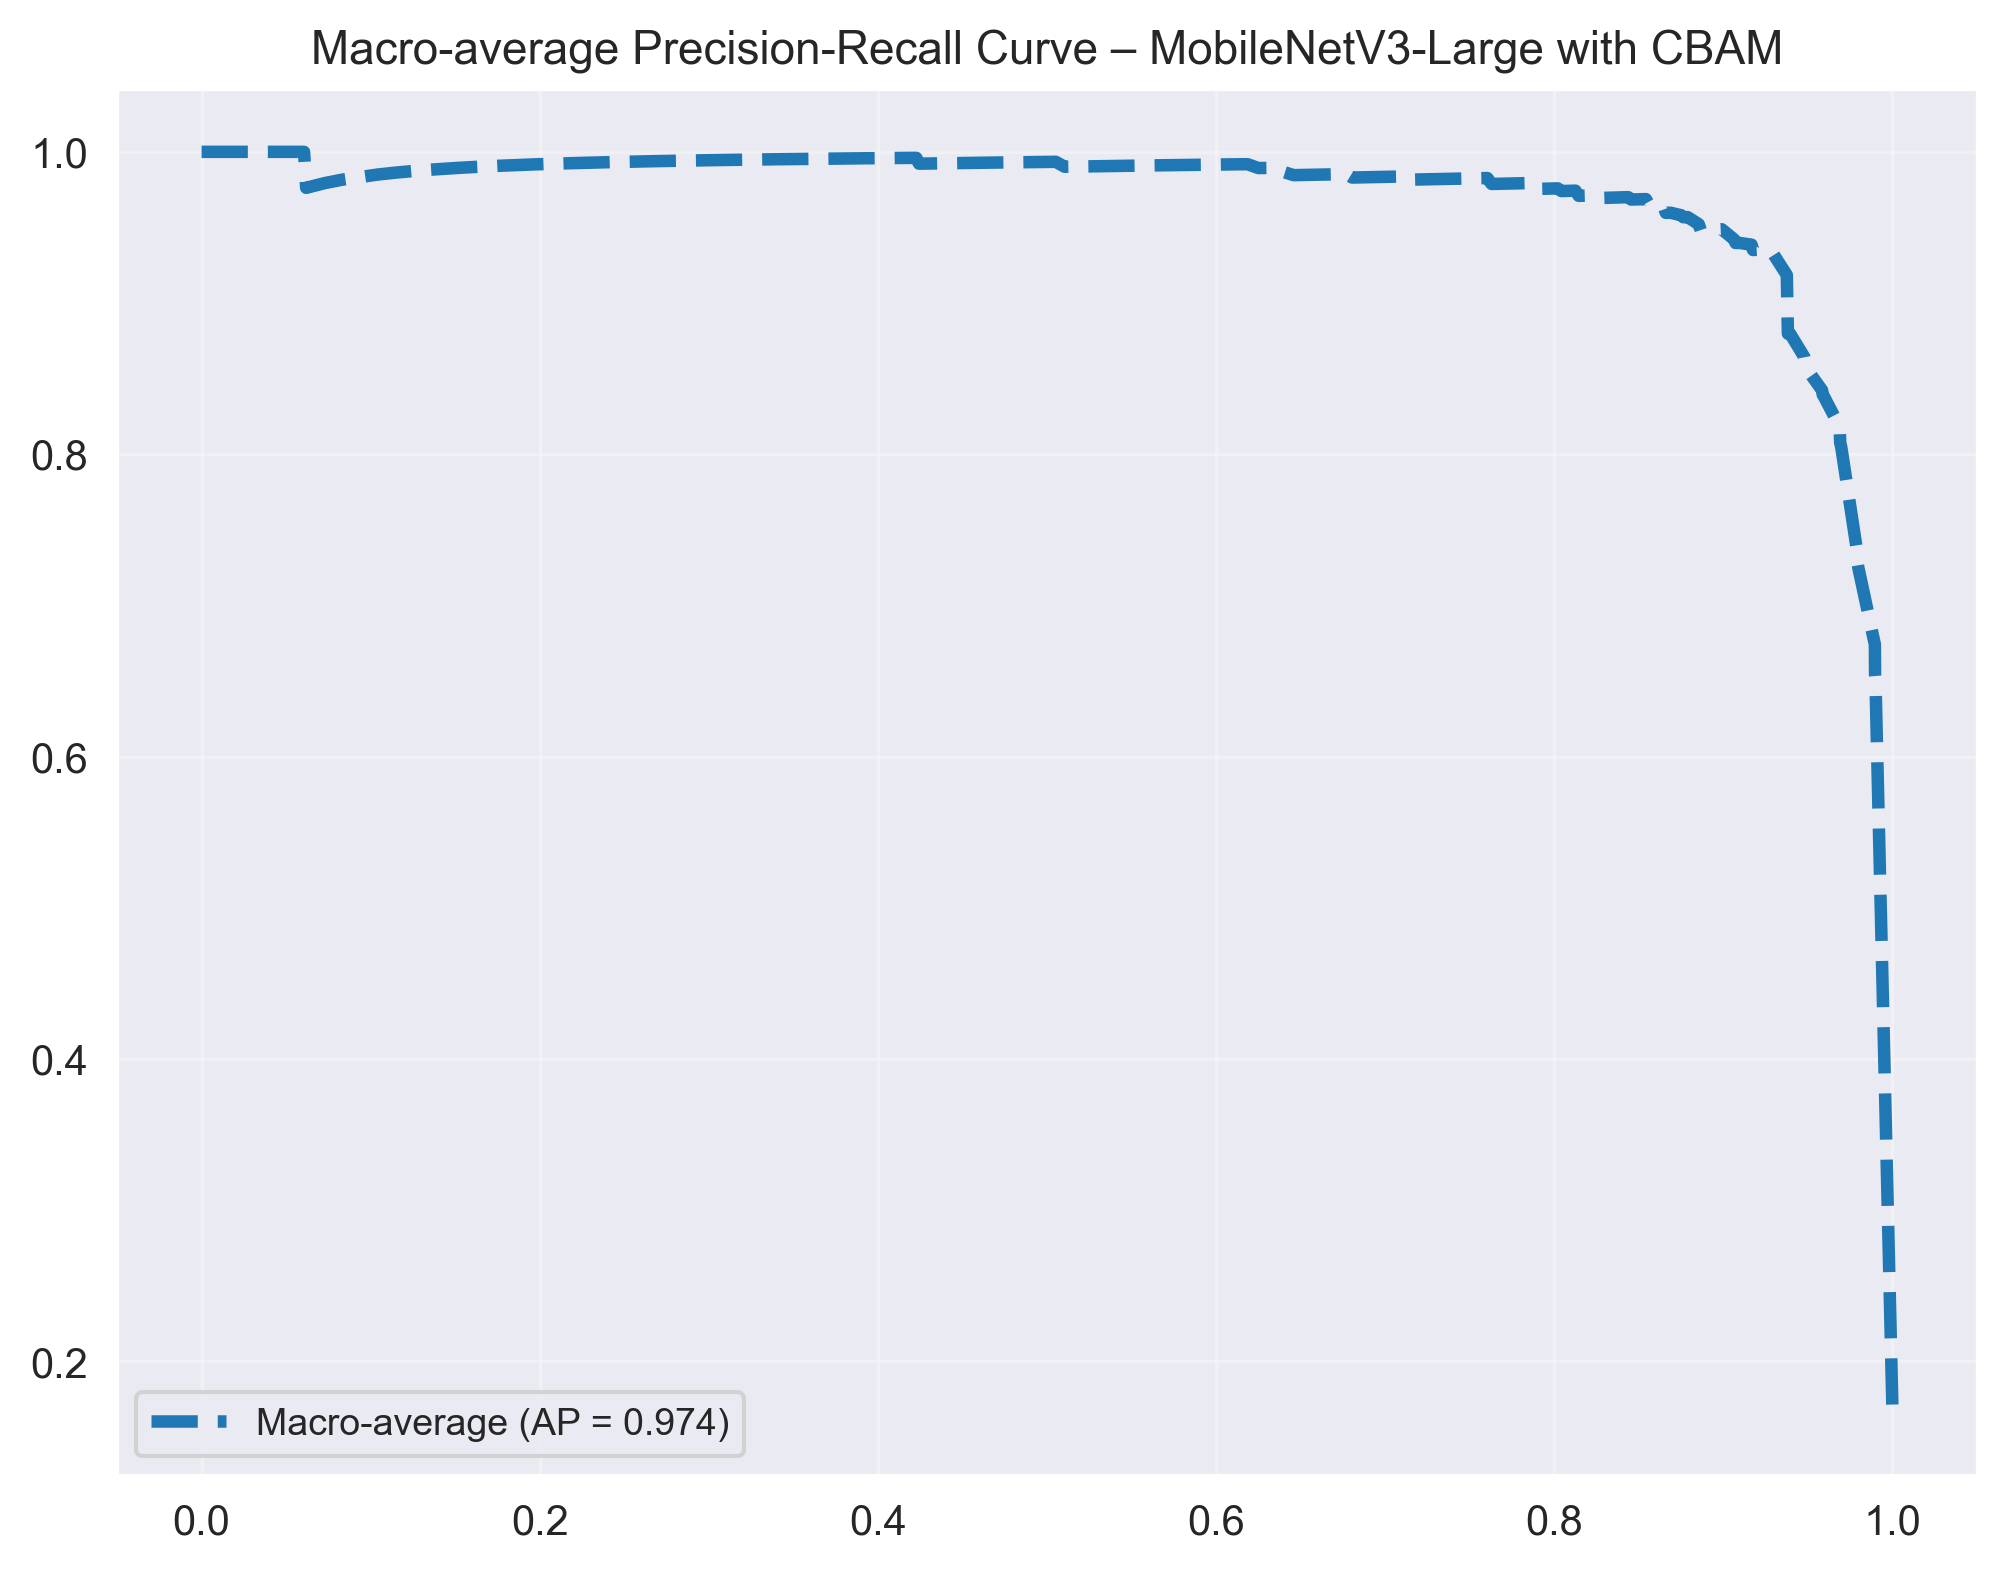

In [20]:
# Compute macro-average PR
all_recall = np.unique(np.concatenate([recall[i] for i in range(n_classes)]))
mean_precision = np.zeros_like(all_recall)

for i in range(n_classes):
    mean_precision += np.interp(all_recall, recall[i][::-1], precision[i][::-1])

mean_precision /= n_classes

macro_ap = np.mean(list(avg_precision.values()))
plt.figure(figsize=(8, 6), dpi=300)
plt.plot(all_recall, mean_precision, linestyle='--', linewidth=3,
         label=f"Macro-average (AP = {macro_ap:.3f})")
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)
plt.title("Macro-average Precision-Recall Curve – MobileNetV3-Large with CBAM", fontsize=11)

plt.show()

In [21]:
model.save("CBAM_mobilenetv3_model.h5")

In [22]:
model.save("CBAM_mobilenetv3_model.keras")